# 🌻 1.5 užduotis (2): Transfer learning ir fine-tuning su savo duomenimis (tf_flowers)

Perdarytas dėstytojo notebook'as **„cnn Transfer learning“ (Transfer learning 2)** su tais pačiais duomenimis kaip 1.4 užduotyje, todėl rezultatus galima tiesiogiai palyginti su CNN, apmokytu nuo nulio.

**Duomenys:** [tf_flowers](https://www.tensorflow.org/datasets/catalog/tf_flowers) – 3 670 tikrų gėlių nuotraukų, 5 klasės (*daisy, dandelion, roses, sunflowers, tulips*), licencija CC BY 2.0 (nuotraukų autoriai nurodyti archyvo `LICENSE.txt`).
Skirtingai nei CIFAR-10 (60 000 vienodų 32×32 paveikslėlių), tai nedidelis rinkinys su skirtingo dydžio nuotraukomis – artimesnis realiai situacijai, kai savų duomenų turima nedaug.

*[Edvin Gladkich, Nojus Sadaunykas]*

> Rekomenduojama: **Runtime → Change runtime type → T4 GPU** (fine-tuning su CPU labai lėtas).

## Kaip veikia originalus notebook'as (Transfer learning 2)

| Žingsnis | Ką daro originalas | Kodėl |
|---|---|---|
| 1. Duomenys | CIFAR-10, pikseliai normalizuojami į [0, 1]. | |
| 2. Požymių išskyrimas | Iš TF Hub įkeliamas **EfficientNetV2-B1** (ImageNet-21k) *feature vector* modelis – tinklas be paskutinio klasifikavimo sluoksnio – kaip `hub.KerasLayer(trainable=False)`. | Užšaldytas tinklas paverčia nuotrauką į 1 280 skaičių požymių vektorių; šie požymiai išmokti iš milijonų nuotraukų ir tinka beveik bet kokiam vaizdų uždaviniui. |
| 3. Modelis | `Resizing(240, 240)` → užšaldytas EfficientNetV2 → `Dense(10)`. Naudojamas `tf_keras` (Keras 2), nes TF Hub sluoksniai nesuderinami su Keras 3. | Mokomas tik paskutinis Dense sluoksnis – greita ir reikia mažai duomenų. |
| 4. Mokymas | 20 epochų, įvertinimas, `save` → zip → `load_model`. | |
| 5. Fine-tuning | Atšildomas visas modelis (`model.trainable = True`), mokymosi greitis sumažinamas 10 kartų, mokoma su **duomenų augmentacija** (apvertimai, pasukimai, ryškumas, poslinkiai). Komentaruose – **~95 %** tikslumas. | Mažu greičiu šiek tiek pritaikomi ir iš anksto išmokti svoriai, nesugadinant jų. |

**Pastebėjimas apie originalą:** pakeitus `trainable` po `compile`, `tf_keras` modelį reikia **sukompiliuoti iš naujo**, kitaip pakeitimas neįsigalioja. Originale `compile` po `model.trainable = True` nekviečiamas, todėl tikėtina, kad fine-tuning metu toliau mokėsi tik Dense sluoksnis. Mūsų versijoje modelis perkompiliuojamas su mažu mokymosi greičiu, o atšildytų parametrų skaičius patikrinamas.

## Ką keičiame
- tf_flowers vietoj CIFAR-10. Nuotraukos įkeliamos iškart 240×240, todėl `Resizing` sluoksnio nereikia.
- Ta pati train / validation / test padalijimo tvarka kaip 1.4 notebook'e (seed 42).
- Duomenys tiekiami per `tf.data` (240×240 nuotraukų masyvas būtų per didelis atminčiai float32 formatu).
- Galutinis palyginimas: CNN nuo nulio (1.4) vs transfer learning vs fine-tuning.

In [1]:
#@title 🔗 SETUP: TF Hub ir tf_keras (kaip originale)
!pip install -q tf_keras tensorflow_hub
import tensorflow_hub as hub
import tf_keras

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


In [2]:
#@title 📥 STEP 1: Gėlių nuotraukų atsisiuntimas ir padalijimas 70:15:15
import pathlib
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

IMG_SIZE = 240
archive = pathlib.Path(tf.keras.utils.get_file("flower_photos.tgz", origin="https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz", extract=True))
search_root = archive if archive.is_dir() else archive.parent
data_dir = next(p.parent for p in search_root.rglob("roses") if p.is_dir())

# Visos nuotraukos sumažinamos iki IMG_SIZE × IMG_SIZE; seed=42 – ta pati tvarka visuose 1.4 ir 1.5 notebook'uose
full_ds = tf.keras.utils.image_dataset_from_directory(data_dir, image_size=(IMG_SIZE, IMG_SIZE), batch_size=None,
                                                      shuffle=True, seed=42)
class_names = full_ds.class_names
pairs = [(x.numpy().astype("uint8"), int(y)) for x, y in full_ds]  # vienu praėjimu: kiekvienas praėjimas sumaišo iš naujo
images = np.stack([x for x, _ in pairs])
labels = np.array([y for _, y in pairs]).reshape(-1, 1)  # forma (n, 1) – kaip CIFAR-10 originale
del pairs

n = len(images)
i_train, i_val = int(0.70 * n), int(0.85 * n)
train_images, val_images, test_images = images[:i_train], images[i_train:i_val], images[i_val:]
train_labels, val_labels, test_labels = labels[:i_train], labels[i_train:i_val], labels[i_val:]
print("Klasės:", class_names)
print(f"train {len(train_images)}, validation {len(val_images)}, test {len(test_images)}; vaizdo forma {images.shape[1:]}")

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 14s 0us/step
Found 3670 files belonging to 5 classes.
Klasės: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
train 2569, validation 550, test 551; vaizdo forma (240, 240, 3)


In [3]:
#@title 🔁 STEP 2: tf.data srautas (normalizavimas į [0, 1] ir paketai)
BATCH = 32
def make_ds(x, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if shuffle:
        ds = ds.shuffle(len(x), seed=42)
    return ds.map(lambda img, label: (tf.cast(img, tf.float32) / 255.0, label)).batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train_images, train_labels, shuffle=True)
val_ds = make_ds(val_images, val_labels)
test_ds = make_ds(test_images, test_labels)

In [4]:
#@title 🧠 STEP 3: Užšaldytas EfficientNetV2-B1 + naujas Dense sluoksnis
feature_extractor_model = "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_b1/feature_vector/2"
IMAGE_SHAPE = (IMG_SIZE, IMG_SIZE)
feature_extractor_layer = hub.KerasLayer(feature_extractor_model, input_shape=IMAGE_SHAPE + (3,), trainable=False)

num_classes = len(class_names)
tf_keras.utils.set_random_seed(42)
model = tf_keras.Sequential([feature_extractor_layer, tf_keras.layers.Dense(num_classes)])
model.compile(optimizer="adam", loss=tf_keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
model.summary()  # mokomi tik Dense sluoksnio parametrai: 1280 · 5 + 5

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 keras_layer (KerasLayer)    (None, 1280)              6931124   
                                                                 
 dense (Dense)               (None, 5)                 6405      
                                                                 
Total params: 6937529 (26.46 MB)
Trainable params: 6405 (25.02 KB)
Non-trainable params: 6931124 (26.44 MB)
_________________________________________________________________


In [5]:
#@title 🏋️ STEP 4: Mokymas (mokomas tik paskutinis sluoksnis)
history = model.fit(train_ds, epochs=8, validation_data=val_ds, verbose=2)
tl_loss, tl_acc = model.evaluate(test_ds, verbose=0)
print(f"Transfer learning test accuracy: {tl_acc:.3f}")

Epoch 1/8
81/81 - 21s - loss: 0.4692 - accuracy: 0.8392 - val_loss: 0.1773 - val_accuracy: 0.9491 - 21s/epoch - 258ms/step
Epoch 2/8
81/81 - 6s - loss: 0.1331 - accuracy: 0.9587 - val_loss: 0.1486 - val_accuracy: 0.9564 - 6s/epoch - 80ms/step
Epoch 3/8
81/81 - 7s - loss: 0.0894 - accuracy: 0.9700 - val_loss: 0.1250 - val_accuracy: 0.9545 - 7s/epoch - 81ms/step
Epoch 4/8
81/81 - 7s - loss: 0.0672 - accuracy: 0.9825 - val_loss: 0.1507 - val_accuracy: 0.9509 - 7s/epoch - 81ms/step
Epoch 5/8
81/81 - 7s - loss: 0.0551 - accuracy: 0.9848 - val_loss: 0.1153 - val_accuracy: 0.9618 - 7s/epoch - 81ms/step
Epoch 6/8
81/81 - 7s - loss: 0.0426 - accuracy: 0.9907 - val_loss: 0.1089 - val_accuracy: 0.9600 - 7s/epoch - 81ms/step
Epoch 7/8
81/81 - 7s - loss: 0.0339 - accuracy: 0.9946 - val_loss: 0.1103 - val_accuracy: 0.9618 - 7s/epoch - 82ms/step
Epoch 8/8
81/81 - 7s - loss: 0.0294 - accuracy: 0.9946 - val_loss: 0.1155 - val_accuracy: 0.9618 - 7s/epoch - 82ms/step
Transfer learning test accuracy: 0.94

In [6]:
#@title 💾 STEP 5: Išsaugojimas ir įkėlimas (kaip originale)
export_path = "saved_model_flowers"
model.save(export_path)
model = tf_keras.models.load_model(export_path, custom_objects={"KerasLayer": hub.KerasLayer})
for layer in model.layers:
    print(f"Layer: {layer.name}, Trainable: {layer.trainable}")

Layer: keras_layer, Trainable: False
Layer: dense, Trainable: True


## 6 žingsnis – fine-tuning
Atšildome visą modelį ir **perkompiliuojame** su 100 kartų mažesniu mokymosi greičiu (1e-5), kad iš anksto išmokti svoriai būtų tik šiek tiek pakoreguoti. Mokymo nuotraukos kiekvieną epochą atsitiktinai keičiamos (augmentacija, kaip originale).

In [7]:
#@title 🔧 STEP 6: Fine-tuning su duomenų augmentacija
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomBrightness(factor=0.1, value_range=(0, 1)),
    tf.keras.layers.RandomTranslation(0.1, 0.1),
])
train_aug_ds = train_ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)

trainable_before = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
model.trainable = True
model.compile(optimizer=tf_keras.optimizers.Adam(learning_rate=1e-5),  # būtina perkompiliuoti, kitaip trainable neįsigalioja
              loss=tf_keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
trainable_after = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print(f"Mokomų parametrų: prieš {trainable_before:,} → po {trainable_after:,}")

history_ft = model.fit(train_aug_ds, epochs=4, validation_data=val_ds, verbose=2)
ft_loss, ft_acc = model.evaluate(test_ds, verbose=0)
print(f"Fine-tuning test accuracy: {ft_acc:.3f}")

Mokomų parametrų: prieš 6,405 → po 6,866,457
Epoch 1/4
81/81 - 86s - loss: 0.7009 - accuracy: 0.7404 - val_loss: 0.2970 - val_accuracy: 0.8818 - 86s/epoch - 1s/step
Epoch 2/4
81/81 - 31s - loss: 0.5595 - accuracy: 0.7980 - val_loss: 0.2712 - val_accuracy: 0.9018 - 31s/epoch - 383ms/step
Epoch 3/4
81/81 - 31s - loss: 0.4553 - accuracy: 0.8369 - val_loss: 0.2509 - val_accuracy: 0.9091 - 31s/epoch - 377ms/step
Epoch 4/4
81/81 - 31s - loss: 0.4316 - accuracy: 0.8435 - val_loss: 0.2297 - val_accuracy: 0.9182 - 31s/epoch - 383ms/step
Fine-tuning test accuracy: 0.915


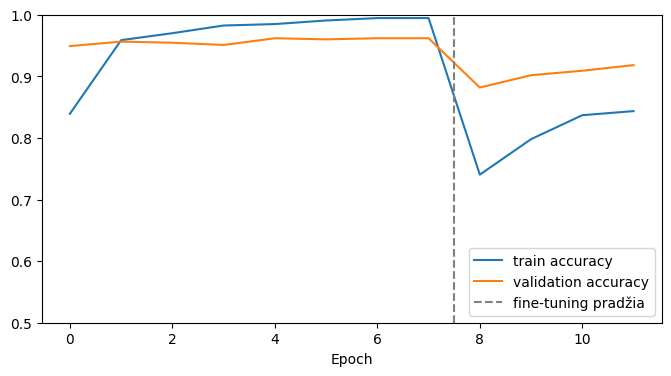

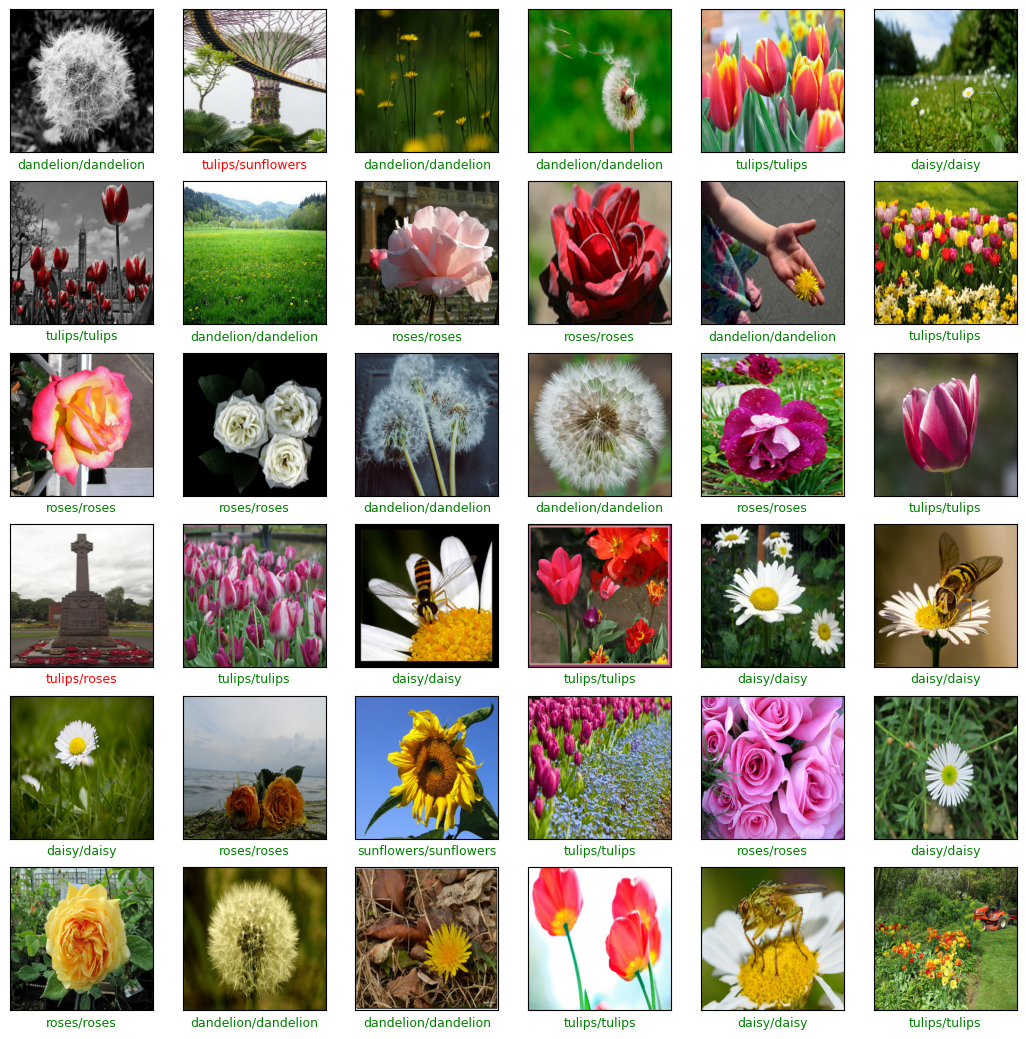

In [8]:
#@title 📊 STEP 7: Mokymo kreivės ir prognozių pavyzdžiai (kaip originale – žalia teisinga, raudona klaida)
acc = history.history["accuracy"] + history_ft.history["accuracy"]
val_acc = history.history["val_accuracy"] + history_ft.history["val_accuracy"]
plt.figure(figsize=(8, 4))
plt.plot(acc, label="train accuracy"); plt.plot(val_acc, label="validation accuracy")
plt.axvline(len(history.history["accuracy"]) - 0.5, color="grey", ls="--", label="fine-tuning pradžia")
plt.ylim([0.5, 1]); plt.xlabel("Epoch"); plt.legend(loc="lower right"); plt.show()

pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)
plt.figure(figsize=(13, 13))
for i in range(36):
    plt.subplot(6, 6, i + 1); plt.xticks([]); plt.yticks([]); plt.grid(False)
    plt.imshow(test_images[i])
    true, guess = class_names[test_labels[i][0]], class_names[pred[i]]
    plt.xlabel(f"{true}/{guess}", color="green" if true == guess else "red", fontsize=9)
plt.show()

,Test accuracy
Modelis,
CNN nuo nulio (1.4),0.722
Transfer learning (užšaldytas EfficientNetV2-B1),0.946
Fine-tuning,0.915


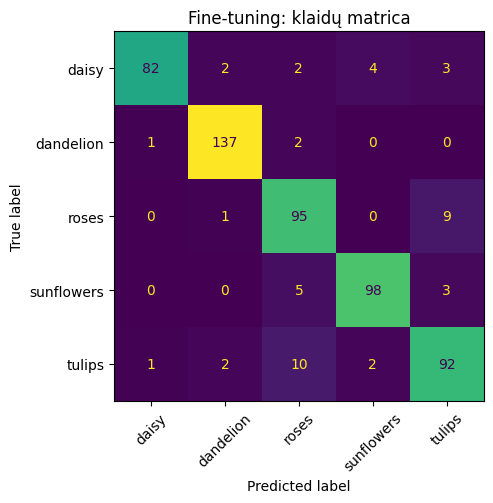

In [9]:
#@title 🏁 STEP 8: Palyginimas su 1.4 užduoties CNN
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

CNN_FROM_SCRATCH_ACC = 0.722  # 1.4 notebook'o „CNN + augmentacija + Dropout“ test accuracy (ta pati testavimo aibė)
results = pd.DataFrame({
    "Modelis": ["CNN nuo nulio (1.4)", "Transfer learning (užšaldytas EfficientNetV2-B1)", "Fine-tuning"],
    "Test accuracy": [CNN_FROM_SCRATCH_ACC, tl_acc, ft_acc],
}).set_index("Modelis").round(3)
display(results)
ConfusionMatrixDisplay.from_predictions(test_labels.ravel(), pred, display_labels=class_names, xticks_rotation=45, colorbar=False)
plt.title("Fine-tuning: klaidų matrica"); plt.show()

## Išvados
| Modelis (ta pati testavimo aibė, 551 nuotrauka) | Mokomų parametrų | Test accuracy |
|---|---|---|
| CNN nuo nulio (1.4) | 466 309 | 0,722 |
| **Transfer learning** (užšaldytas EfficientNetV2-B1 + Dense) | 6 405 | **0,946** |
| Fine-tuning (atšildytas visas modelis, 4 epochos) | 6 866 457 | 0,915 |

- **Transfer learning** pagerino rezultatą 22 procentiniais punktais, palyginti su CNN, apmokytu nuo nulio, nors mokoma tik 6 405 parametrų (1 280 požymių × 5 klasės + 5). Jau po pirmos epochos validavimo tikslumas 94,9 %: ImageNet-21k išmokti požymiai tinka ir gėlėms.
- **Fine-tuning šiuo atveju rezultatą pablogino** (0,946 → 0,915). Pirmą epochą validavimo tikslumas nukrito iki 88 %, vėliau atsistatė iki 91,8 %, bet užšaldyto modelio per 4 epochas nepasiekė. Priežastys: ~6,9 mln. parametrų mokomi su vos ~2 600 nuotraukų; atšildžius modelį, BatchNorm sluoksniai pereina į mokymo režimą ir perskaičiuoja statistiką pagal mažus paketus (32); augmentacija keičia mokymo duomenų pasiskirstymą.
- Tai patvirtina originalo analizėje pastebėtą problemą: be pakartotinio `compile` atšildymas neįsigalioja. Tikėtina, kad originale fine-tuning metu toliau buvo mokomas tik Dense sluoksnis, todėl tikslumas nekrito.
- Fine-tuning labiausiai pasiteisina, kai savų duomenų daug arba jie labai skiriasi nuo ImageNet. Mažiems rinkiniams geriau palikti modelį užšaldytą arba atšildyti tik paskutinius blokus su dar mažesniu mokymosi greičiu ir daugiau epochų.
- **Išvada projektui:** sporto įrangai atpažinti iš vartotojo nuotraukų (1.5 (1) dalyje matėme, kad svarstis painiojamas su hanteliais) pakaktų užšaldyto EfficientNetV2 su nauju Dense sluoksniu, kelių šimtų nuotraukų kiekvienai klasei ir kelių minučių mokymo.